In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

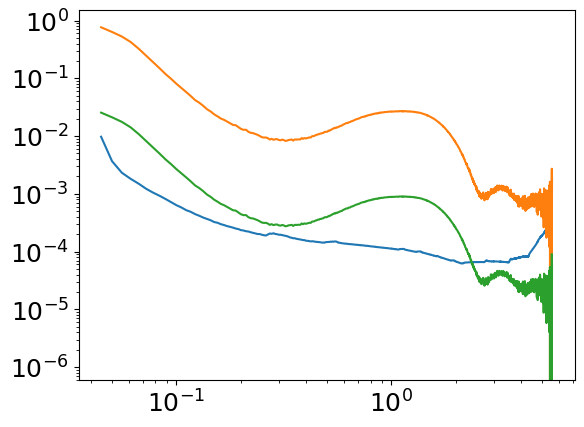

In [2]:
sample = "BIV_S9" # "BIV_S8_15mM_LV4_50uM_aSynWT"
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr = np.loadtxt(sub_dat_path, unpack=True)

plt.loglog(q, Ierr)
plt.loglog(q, I)
plt.loglog(q, I/30)





#### Test Initial Guesses first

In [9]:
# ellipsoidal sym
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale: fit.ULV_ellipsoid(q, R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale,   0, 0, 0)
plt.close("all")

param_set = "ULV_ellipsoid"

q     = q
I     = I 
I_err = Ierr # np.maximum(I, 0) / 30

# ========================== Parameters ==========================
R = 10.5
sigma_R = 7.13
eps = 0.98
sigma_eps = 0.2
rho_h = 1.6
sigma_h = 0.35
sigma_c = 0.77
z_h = 1.8
scale = 1e-7
c2 = 0
c3 = 0
c4 = 0.007
# [10.471, 7.133, 0.98558, 0.21418, 1.4986, 1.7302,  0.37497,  0.20002,  0.75887, 1.8633, 8.08e-6]
# ========================== Setting Bounds ==============================
# popt = [        R_fit,  sigma_R_fit,     eps_fit, sigma_eps_fit,  rho_h_fit, sigma_h_fit,  sigma_c_fit,      z_h_fit,    scale_fit,   c2_fit,   c3_fit,       c4_fit]
p0           = [        R,  sigma_R,     eps, sigma_eps,  rho_h, sigma_h,    sigma_c,      z_h,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,     0.8,         0,      0,     0.2,        0.5,      1.5,  -np.inf] # ,    0,    0,  -np.inf]
upper_bounds = [       25,        9,     1.5,       0.7,     10,     0.5,          1,        2,  +np.inf] # ,  0.2,  0.5,  +np.inf]
#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q, I, sigma=I_err, maxfev=1000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = fit.param_names.get(param_set)

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = q
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using ellip_sym (op. error)')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
# legend.set_title(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
# fig=fit.EDP_plot(R, sigma_h_fit, sigma_h_fit, sigma_c_fit, rho_h_fit, rho_h_fit, z_h_fit, z_h_fit, info_text, 
#              f'{sample} fac={fac} using {fit_function.__name__}')
fig=fit.EDP_plot(R, sigma_h, sigma_h, sigma_c, rho_h, rho_h, z_h, z_h, "_", 
             f'{BM29.sample_dict[sample]} using ellip_sym (initial guess)')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

# pow_law_reality_check(c2_fit, c3_fit, c4_fit)


Computing I(q):  12%|██▊                     | 115/1000 [00:01<00:14, 61.67it/s]


KeyboardInterrupt: 

Computing I(q): 100%|████████████████████████| 500/500 [00:03<00:00, 152.40it/s]


NameError: name 'info_text_print' is not defined

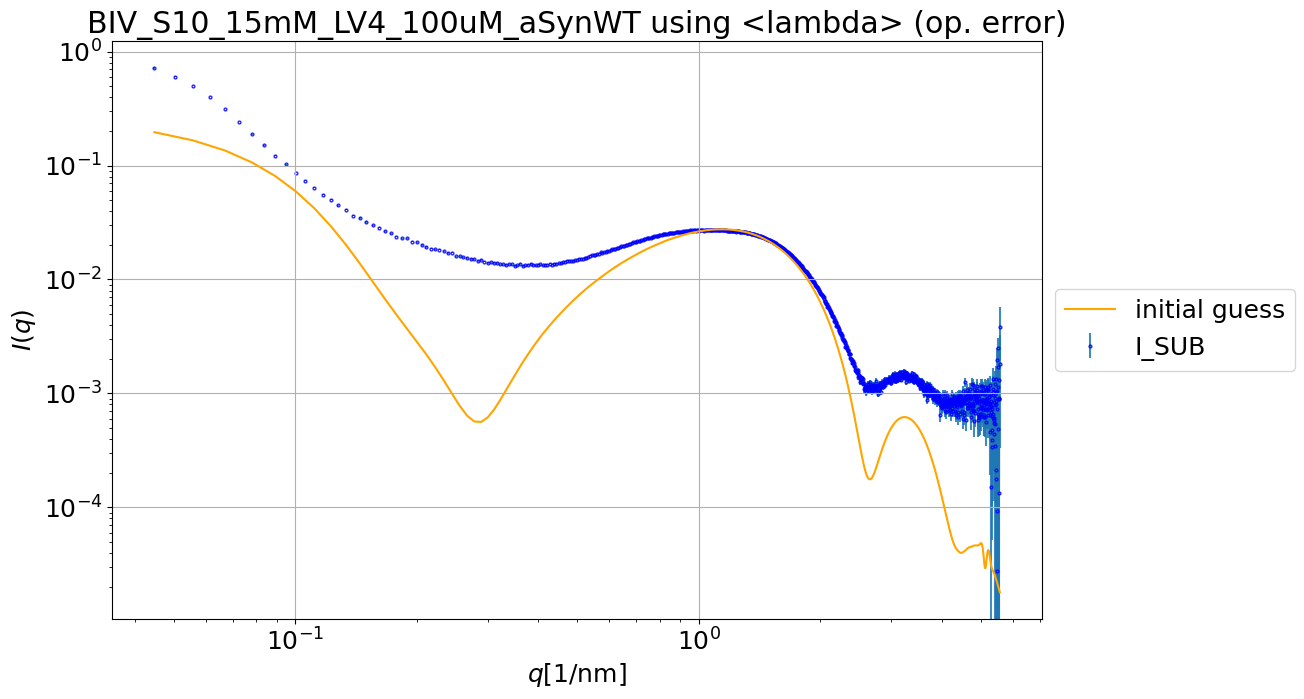

In [10]:
# ellipsoidal asym NO BGR test
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h1, sigma_h1,  rho_h2, sigma_h2,    sigma_c,      z_h,    scale: fit.ULV_ellipsoid_asym(q, R,  sigma_R,     eps, sigma_eps,  rho_h1, sigma_h1,  rho_h2, sigma_h2,    sigma_c,      z_h,    scale,   0, 0, 0)
plt.close("all")

param_set = "ULV_ellipsoid_asym"

q     = q
I     = I 
I_err = Ierr # np.maximum(I, 0) / 30
I_err_op = np.maximum(I, 0.01) / 30
I_err_op20 = np.maximum(I, 0.01) / 20

thinning = 2
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================
# ======================================================================
R = 10      
sigma_R = 6
eps = 1.13
sigma_eps = 0.1
rho_h1 = 1.88
rho_h2 = 1.04
sigma_h1 = 0.3
sigma_h2 = 0.44
sigma_c = 0.9
z_h = 1.75
scale = 5e-7
# ========================== Setting Bounds ==============================
p0           = [        R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,     0.8,         0,       0,      0,        0.2,      0.2,      0.5,      1.5,  -np.inf] #,    0,    0,  -np.inf]
upper_bounds = [       25,        9,     1.5,       0.7,      10,     10,        0.5,      0.5,        1,        2,  +np.inf] # ,  0.2,  0.5,  +np.inf]

#======================== Fit ===========================================
# popt, pcov = curve_fit(fit_function, q_thinned, I_thinned, sigma=I_err_thinned, maxfev=1000, p0=p0, bounds = (lower_bounds, upper_bounds))

# param_names = fit.param_names.get(param_set)

# perr = np.sqrt(np.diag(pcov))
# for name, value in zip(param_names, popt):
#     globals()[name] = value
# chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), len(q_thinned))
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
# plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='pow law bgr')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using {fit_function.__name__} (op. error)')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_FINAL_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
# fig=fit.EDP_plot(R, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text, 
#              f'{BM29.sample_dict[sample]} using {fit_function.__name__}')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

In [12]:
# ellipsoidal asym NO BGR 
fit_function = lambda q,  R,  sigma_R,     eps, sigma_eps,  rho_h1, sigma_h1,  rho_h2, sigma_h2,    sigma_c,      z_h,    scale: fit.ULV_ellipsoid_asym(q, R,  sigma_R,     eps, sigma_eps,  rho_h1, sigma_h1,  rho_h2, sigma_h2,    sigma_c,      z_h,    scale,   0, 0, 0)
plt.close("all")

param_set = "ULV_ellipsoid_asym"

q     = q
I     = I 
I_err = np.abs(I / 30) #Ierr

thinning = 2
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================
# ======================================================================
R = 10      
sigma_R = 6
eps = 1.13
sigma_eps = 0.1
rho_h1 = 1.88
rho_h2 = 1.04
sigma_h1 = 0.3
sigma_h2 = 0.44
sigma_c = 0.9
z_h = 1.75
scale = 5e-7
# ========================== Setting Bounds ==============================
p0           = [        R,  sigma_R,     eps, sigma_eps,  rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,     0.8,         0,       0,      0,        0.2,      0.2,      0.5,      1.5,  -np.inf] #,    0,    0,  -np.inf]
upper_bounds = [       25,        9,     1.5,       0.7,      10,     10,        0.5,      0.5,        1,        2,  +np.inf] # ,  0.2,  0.5,  +np.inf]

#======================== Fit ===========================================
popt, pcov = curve_fit(fit_function, q_thinned, I_thinned, sigma=I_err_thinned, maxfev=1000, p0=p0, bounds = (lower_bounds, upper_bounds))

param_names = fit.param_names.get(param_set)

perr = np.sqrt(np.diag(pcov))
for name, value in zip(param_names, popt):
    globals()[name] = value
chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), len(q_thinned))
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='pow law bgr')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using {fit_function.__name__} (op. error)')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
legend.set_title(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_FINAL_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
fig=fit.EDP_plot(R, sigma_h1_fit, sigma_h2_fit, sigma_c_fit, rho_h1_fit, rho_h2_fit, z_h_fit, z_h_fit, info_text_print, 
             f'{BM29.sample_dict[sample]} using ellip_asym (op. error)')
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)

Computing I(q):  82%|███████████████████▌    | 408/500 [00:03<00:00, 109.48it/s]


KeyboardInterrupt: 

Computing I(q): 100%|██████████████████████| 1000/1000 [00:01<00:00, 504.76it/s]


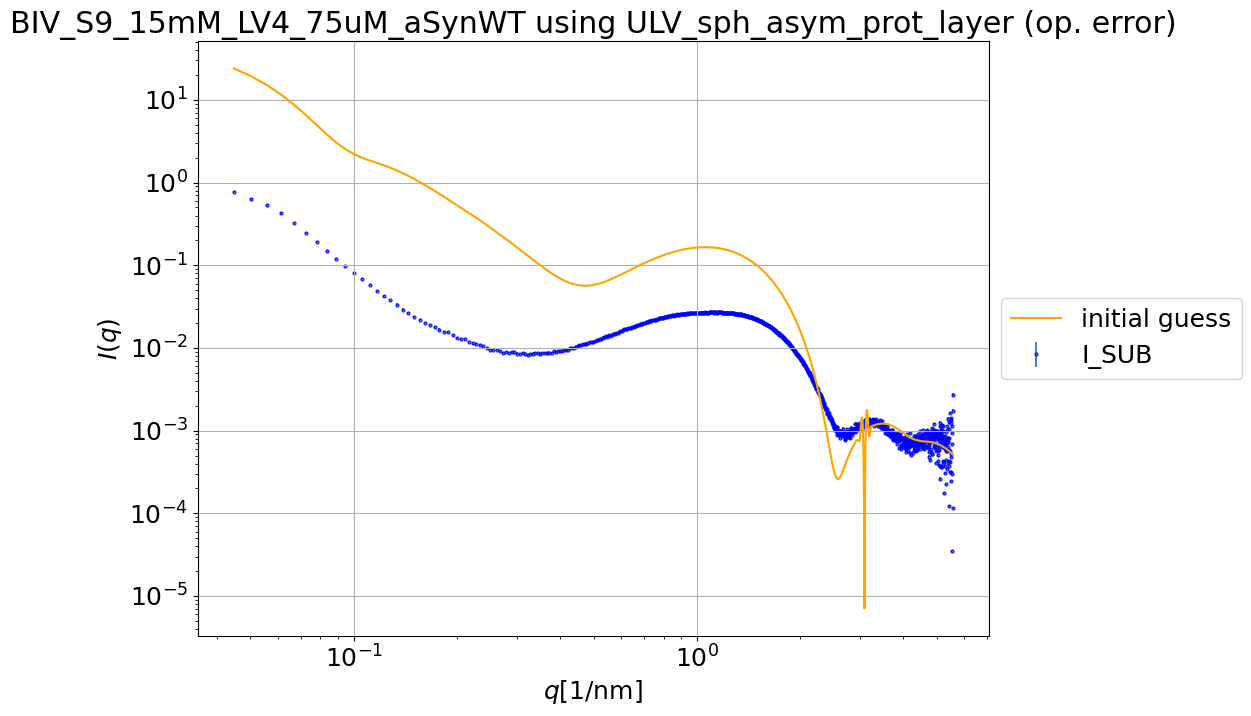

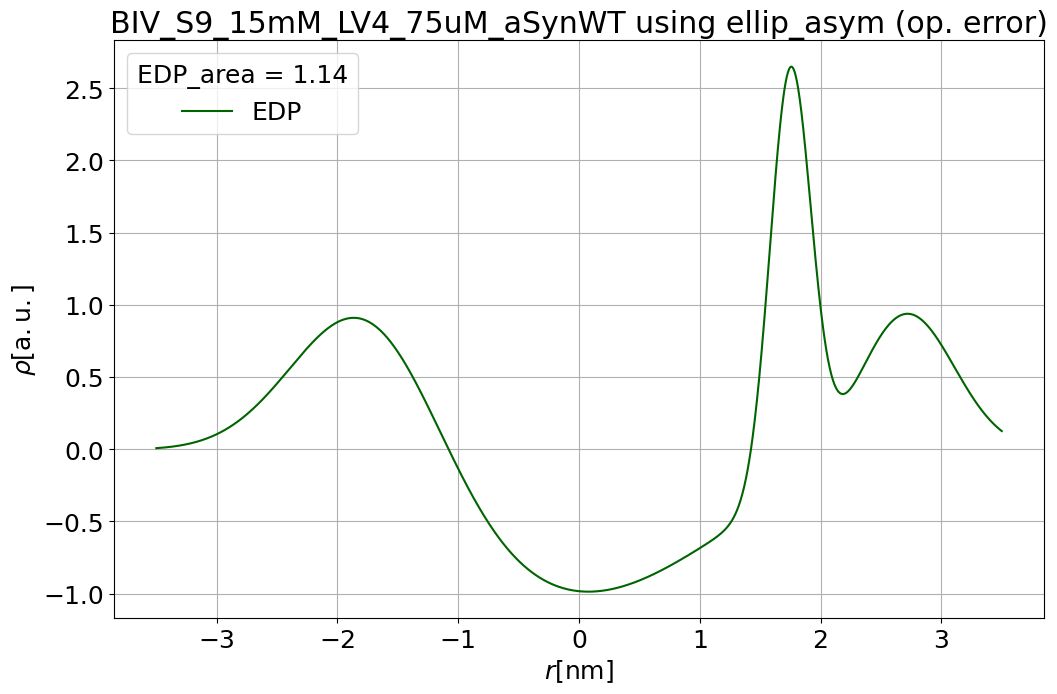

In [15]:
# Test additional protein layer

fit_function = lambda q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale: fit.ULV_sph_asym_prot_layer(q, R, sigma_R, rho_h1, rho_h2, sigma_h1, sigma_h2, sigma_c, z_h, z_h3, sigma_h3, rho_h3, scale, 0, 0, 0)

q     = q
I     = I 
I_err = np.abs(I / 30) #Ierr

thinning = 1
q_thinned = q[::thinning]
I_thinned = I[::thinning]
I_err_thinned = I_err[::thinning]

# ========================== Parameters ==========================
# ======================================================================
R = 20
sigma_R = 10
rho_h1 = 1.2
rho_h2 = 2.9
sigma_h1 = 0.6
sigma_h2 = 0.17
sigma_c = 1.15
z_h = 1.75
z_h3 = 2.7
sigma_h3 = 0.4
rho_h3 = 1.0
scale = 5e-7
# ========================== Setting Bounds ==============================
p0           = [        R,  sigma_R,       rho_h1, rho_h2,   sigma_h1, sigma_h2,  sigma_c,      z_h,  z_h3, sigma_h3,   rho_h3,    scale] # ,   c2,   c3,       c4]
lower_bounds = [        9,        2,          0.4,    0.4,        0.2,      0.2,      0.5,      1.5,     2,      0.2,      0.5,  -np.inf] #,    0,    0,  -np.inf]
upper_bounds = [       25,        9,            4,      4,        0.5,      0.5,        1,        2,     5,        1,      2.0,  +np.inf] # ,  0.2,  0.5,  +np.inf]

#======================== Fit ===========================================
# popt, pcov = curve_fit(fit_function, q_thinned, I_thinned, sigma=I_err_thinned, maxfev=10000, p0=p0, bounds = (lower_bounds, upper_bounds))

# param_names = ["R_fit", "sigma_R_fit", "rho_h1_fit", "rho_h2_fit",
#                                 "sigma_h1_fit", "sigma_h2_fit", "sigma_c_fit","z_h_fit", "z_h3_fit", "sigma_h3_fit", "rho_h3_fit", "scale_fit"]

# perr = np.sqrt(np.diag(pcov))
# for name, value in zip(param_names, popt):
#     globals()[name] = value
# chi2, info_text_print = fit.all_info(q, I, I_err, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)
# #=========================== Plot ===========================================

q_fit = np.linspace(min(q), max(q), len(q_thinned))
plt.figure(figsize=(12, 7.5))
plt.errorbar(q, I, I_err, marker="o", markersize=2,markeredgewidth=1,markeredgecolor='Blue', markerfacecolor='None', alpha=0.85, ls="None", label='I_SUB', zorder=1)
# plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2_fit, c3_fit, c4_fit), color='black', label='pow law bgr')
#plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, c2, c3, c4), color='black', label='initial bgr', ls="--")

plt.xlabel('$q [1/\\mathrm{nm}]$')
plt.ylabel('$I(q)$')
plt.title(f'{BM29.sample_dict[sample]} using ULV_sph_asym_prot_layer (op. error)')
plt.grid(True)
plt.legend()
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
# legend.set_title(info_text_print)
# print(info_text_print)

plt.tight_layout()
# plt.savefig(target_folder / f"LV4_{fit_function.__name__}_FINAL_Jan31.png", bbox_inches='tight', pad_inches=0.05)
plt.show()
info_text="_"
#==================== EDP Plot ==================================================
fig=fit.EDP_plot(R, sigma_h1, sigma_h2, sigma_c, rho_h1, rho_h2, z_h, z_h, info_text,  f'{BM29.sample_dict[sample]} using ellip_asym (op. error)', z_h3, sigma_h3, rho_h3)
# fig.savefig(target_folder / f"LV4_EDP_{fit_function.__name__}_FINAL.png", dpi=400, bbox_inches='tight', pad_inches=0.05)
